# 05 · Tinh chỉnh tham số bằng RandomizedSearchCV

**Bài toán:** dự đoán bụi mịn PM2.5 ở giờ kế tiếp (t+1) của cùng một trạm.

**Notebook này làm gì (theo thứ tự):**
1. Nạp dữ liệu, tạo đặc trưng, chia 5 lượt ôn thi thử bằng đúng mã trong `src/` (giống Notebook 02, 03, 04).
2. Với **Gradient Boosting** và **Random Forest**: thử nhiều bộ tham số ngẫu nhiên bằng `RandomizedSearchCV`, chấm bằng RMSE trên 5 lượt chia theo thời gian.
3. Chọn bộ tham số có **RMSE trung bình 5 lượt thấp nhất**, rồi chấm lại đầy đủ như Notebook 03 và 04 (MAE, RMSE, R², kiểm tra học vẹt).
4. So sánh **trước và sau** khi tinh chỉnh.
5. Lưu mô hình, điểm, bảng các lần thử và ghi sổ thí nghiệm (`*_tuned_cv5`).

**RandomizedSearchCV là gì (giải thích ngắn):** mô hình có các "nút vặn" (tham số) phải đặt trước khi học. Thay vì thử mọi tổ hợp (rất lâu), công cụ này **bốc ngẫu nhiên** `n_iter` tổ hợp trong khoảng cho trước, mỗi tổ hợp được chấm bằng đúng 5 lượt chia theo thời gian của nhóm (`cv=folds`), rồi chọn tổ hợp có điểm tốt nhất.

**Quy tắc phải giữ:**
- **Không dùng tập Test** để chọn hay chỉnh mô hình. Notebook này không dự đoán hay chấm điểm trên Test.
- Chọn bộ tham số theo **RMSE trung bình 5 lượt** (đúng yêu cầu: chọn theo RMSE validation). Cột trung bình lượt 2-5 chỉ để tham khảo vì lượt 1 thiếu mùa đông.
- Tham số nào không nằm trong khoảng tìm kiếm thì giữ cố định (hạt giống 42; Gradient Boosting vẫn `early_stopping=False`).
- Điểm CV của bộ tốt nhất hơi **lạc quan**, vì nó được chọn ra từ nhiều lần thử trên chính các lượt này. Con số trung thực cuối cùng là điểm Test, chỉ chạy **một lần** sau khi nhóm đã khóa cấu hình.

**Cách chạy:** chọn *Run All*. Cần có sẵn các file do notebook 03 và 04 tạo ra (`outputs/random_forest_cv_metrics.csv`, `outputs/gradient_boosting_cv_metrics.csv`) và `experiment_log.csv`. Thời gian chạy lâu (ước tính từ vài chục phút đến khoảng một giờ trên máy thường); nếu cần chạy thử nhanh thì giảm `N_ITER_GB`, `N_ITER_RF` ở mục 1.

## 1. Cấu hình và nạp thư viện

Các "công tắc" ở ô dưới:
- `SAVE_ARTIFACTS`: `True` thì ghi mô hình, điểm, biểu đồ, sổ thí nghiệm ra file; `False` thì chỉ chạy để xem.
- `SAVE_OOF`: `True` thì lưu thêm file dự đoán từng dòng của mô hình đã tinh chỉnh (khoảng 28 MB mỗi mô hình). Mặc định tắt.
- `TUNE_GRADIENT_BOOSTING`, `TUNE_RANDOM_FOREST`: bật/tắt từng mô hình.
- `N_ITER_GB`, `N_ITER_RF`: số bộ tham số ngẫu nhiên thử cho mỗi mô hình (Random Forest chậm hơn nên thử ít hơn).

In [15]:
import json
import sys
import time
from datetime import datetime
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import sklearn
from IPython.display import display
from scipy.stats import loguniform
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.model_selection import RandomizedSearchCV
from sklearn.pipeline import Pipeline

# Tìm thư mục gốc của đồ án (thư mục chứa src/), chạy được từ gốc hoặc từ notebooks/.
CURRENT_DIR = Path.cwd().resolve()
PROJECT_ROOT = next(
    (path for path in [CURRENT_DIR, *CURRENT_DIR.parents] if (path / "src").is_dir()),
    None,
)
if PROJECT_ROOT is None:
    raise FileNotFoundError("Không tìm thấy thư mục gốc dự án (thư mục chứa src/).")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# Dùng lại mã chung của nhóm (không tự viết lại cách chia dữ liệu).
from src.data_loader import load_data, time_split, cv_folds, TEST_START
from src.features import (
    FEATURE_COLUMNS,
    FFILL_LIMIT,
    PM25_LAGS,
    ROLLING_WINDOWS,
    add_features,
    build_preprocessor,
    split_xy,
)

RANDOM_STATE = 42               # hạt giống: cố định để ai chạy lại cũng ra đúng kết quả
SAVE_ARTIFACTS = True           # True: ghi file kết quả; False: chỉ chạy xem
SAVE_OOF = False                # True: lưu dự đoán từng dòng (~28 MB mỗi mô hình)
TUNE_GRADIENT_BOOSTING = True
TUNE_RANDOM_FOREST = True
N_ITER_GB = 20               # số bộ tham số thử cho Gradient Boosting
N_ITER_RF = 8                   # số bộ tham số thử cho Random Forest (chậm hơn nên ít hơn)

MODELS_DIR = PROJECT_ROOT / "models"
OUTPUTS_DIR = PROJECT_ROOT / "outputs"
FIGURES_DIR = OUTPUTS_DIR / "figures"
EXPERIMENT_LOG = PROJECT_ROOT / "experiment_log.csv"

# Đồng bộ kiểu biểu đồ với Notebook 02, 03, 04.
plt.rcParams["figure.dpi"] = 100
plt.rcParams["savefig.dpi"] = 150
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.25

SAVED_FIGURES = []


def save_figure(fig, filename):
    """Lưu biểu đồ PNG vào outputs/figures khi SAVE_ARTIFACTS=True."""
    if SAVE_ARTIFACTS:
        FIGURES_DIR.mkdir(parents=True, exist_ok=True)
        figure_path = FIGURES_DIR / filename
        fig.savefig(figure_path, dpi=150, bbox_inches="tight")
        SAVED_FIGURES.append(figure_path)
        print("Đã lưu hình:", figure_path.relative_to(PROJECT_ROOT))
    return fig


print("Thư mục gốc dự án:", PROJECT_ROOT)
print("scikit-learn:", sklearn.__version__)
print("pandas:", pd.__version__)
print("Mốc bắt đầu Test:", TEST_START)
print("SAVE_ARTIFACTS =", SAVE_ARTIFACTS, "| SAVE_OOF =", SAVE_OOF)
print("Tinh chỉnh: GB =", TUNE_GRADIENT_BOOSTING, f"(n_iter={N_ITER_GB})",
      "| RF =", TUNE_RANDOM_FOREST, f"(n_iter={N_ITER_RF})")

Thư mục gốc dự án: C:\Users\Admin\Documents\GitHub\sgu_finalproject_machinelearning_2026-2027
scikit-learn: 1.7.2
pandas: 2.3.3
Mốc bắt đầu Test: 2016-09-01 00:00:00
SAVE_ARTIFACTS = True | SAVE_OOF = False
Tinh chỉnh: GB = True (n_iter=20) | RF = True (n_iter=8)


## 2. Nạp dữ liệu và tạo đặc trưng

Cùng quy trình với Notebook 02, 03, 04: `add_features` tạo **cột đáp án `target`** (bụi PM2.5 giờ kế tiếp, cùng trạm) và các **đặc trưng**; dòng thiếu `target` bị bỏ.

In [16]:
raw = load_data()
featured = add_features(raw)
labeled = featured.dropna(subset=["target"]).reset_index(drop=True)

print(f"Dữ liệu gốc            : {raw.shape[0]:,} dòng x {raw.shape[1]} cột")
print(f"Sau khi tạo đặc trưng  : {featured.shape[0]:,} dòng x {featured.shape[1]} cột")
print(f"Sau khi bỏ dòng thiếu target: {labeled.shape[0]:,} dòng")
print(f"Số trạm                : {labeled['station'].nunique()}")
print(f"Số đặc trưng đưa vào mô hình: {len(FEATURE_COLUMNS)}")

Dữ liệu gốc            : 420,768 dòng x 19 cột
Sau khi tạo đặc trưng  : 420,768 dòng x 35 cột
Sau khi bỏ dòng thiếu target: 412,017 dòng
Số trạm                : 12
Số đặc trưng đưa vào mô hình: 27


## 3. Chia dữ liệu và tạo đúng 5 lượt ôn thi thử

Giống Notebook 04: phần học/ôn thi thử (target đến hết tháng 8/2016) tách khỏi phần thi cuối (từ 01/09/2016), phần học cắt thành **5 lượt** theo thời gian. Các `assert` bảo đảm không dữ liệu thi nào lọt vào phần học. `folds` là danh sách các cặp (chỉ số học, chỉ số thử) và sẽ được đưa thẳng vào `RandomizedSearchCV` ở mục 6.

In [17]:
train_validation, test = time_split(labeled)
train_validation = train_validation.reset_index(drop=True)
test = test.reset_index(drop=True)

X_tv, y_tv = split_xy(train_validation)   # X = đề bài (27 đặc trưng), y = đáp án (target)
folds = cv_folds(train_validation, n_splits=5)

fold_rows = []
for fold_id, (tr, va) in enumerate(folds, start=1):
    train_times = train_validation.iloc[tr]["target_datetime"]
    validation_times = train_validation.iloc[va]["target_datetime"]
    fold_rows.append({
        "fold": fold_id,
        "train_rows": len(tr),
        "validation_rows": len(va),
        "train_start": train_times.min(),
        "train_end": train_times.max(),
        "validation_start": validation_times.min(),
        "validation_end": validation_times.max(),
    })

fold_table = pd.DataFrame(fold_rows)
display(fold_table)

assert len(folds) == 5, f"Cần đúng 5 lượt, hiện có {len(folds)}."
assert train_validation["target_datetime"].max() < TEST_START
assert test["target_datetime"].min() >= TEST_START
for tr, va in folds:
    assert np.intersect1d(tr, va).size == 0, "Phần học và phần thử bị trùng dòng."
    assert (
        train_validation.iloc[tr]["target_datetime"].max()
        < train_validation.iloc[va]["target_datetime"].min()
    ), "Phần thử không nằm sau phần học."

print(f"Phần học/ôn thi thử: {len(train_validation):,} dòng")
print(f"Phần thi cuối      : {len(test):,} dòng (giữ riêng, KHÔNG dùng trong notebook này)")
print("Kiểm tra thứ tự thời gian và 5 lượt: PASS")

,fold,train_rows,validation_rows,train_start,train_end,validation_start,validation_end
0,1,60258,60595,2013-03-01 01:00:00,2013-09-30 00:00:00,2013-09-30 01:00:00,2014-05-01 17:00:00
1,2,120853,59958,2013-03-01 01:00:00,2014-05-01 17:00:00,2014-05-01 18:00:00,2014-11-30 16:00:00
2,3,180811,59858,2013-03-01 01:00:00,2014-11-30 16:00:00,2014-11-30 17:00:00,2015-07-02 02:00:00
3,4,240669,60217,2013-03-01 01:00:00,2015-07-02 02:00:00,2015-07-02 03:00:00,2016-01-31 14:00:00
4,5,300886,60068,2013-03-01 01:00:00,2016-01-31 14:00:00,2016-01-31 15:00:00,2016-08-31 23:00:00


Phần học/ôn thi thử: 360,954 dòng
Phần thi cuối      : 51,063 dòng (giữ riêng, KHÔNG dùng trong notebook này)
Kiểm tra thứ tự thời gian và 5 lượt: PASS


## 4. Khoảng tìm kiếm tham số

Hai mô hình đều nằm trong dây chuyền `tiền xử lý → mô hình` (giống Notebook 03 và 04), nên tên tham số có tiền tố `model__`. Tiền xử lý chỉ học từ phần học của từng lượt nên không nhìn trộm phần thử.

**Gradient Boosting** (`HistGradientBoostingRegressor`, `early_stopping=False`):

| Tham số | Khoảng thử | Ý nghĩa dễ hiểu |
|---|---|---|
| `learning_rate` | 0,02 đến 0,3 (lấy mẫu theo thang log) | Mỗi cây sửa bao nhiêu phần sai còn lại |
| `max_iter` | 100, 200, 300, 500 | Số cây nối tiếp |
| `max_leaf_nodes` | 15, 31, 63, 127 | Độ phức tạp tối đa của mỗi cây |
| `min_samples_leaf` | 20, 50, 100, 200 | Số mẫu tối thiểu mỗi lá (lớn thì cây bớt học vẹt) |
| `l2_regularization` | 0, 0,1, 1, 10 | Phạt độ phức tạp |

**Random Forest:**

| Tham số | Khoảng thử | Ý nghĩa dễ hiểu |
|---|---|---|
| `n_estimators` | 50, 100, 200 | Số cây (hiện đang dùng 20) |
| `max_depth` | 12, 16, 24, không giới hạn | Độ sâu tối đa của cây |
| `min_samples_leaf` | 2, 5, 10, 20 | Số mẫu tối thiểu mỗi lá |
| `max_features` | 0,3, 0,5, 0,7, 1,0 | Tỉ lệ đặc trưng mỗi cây được xem ở mỗi lần chia |

In [18]:
def build_model(kind, params=None):
    """Tạo dây chuyền mới tinh; params dùng tên có tiền tố model__ (như RandomizedSearchCV)."""
    if kind == "gradient_boosting":
        estimator = HistGradientBoostingRegressor(
            early_stopping=False, random_state=RANDOM_STATE
        )
    elif kind == "random_forest":
        estimator = RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)
    else:
        raise ValueError(kind)
    pipeline = Pipeline([
        ("prep", build_preprocessor(scale=False)),
        ("model", estimator),
    ])
    if params:
        pipeline.set_params(**params)
    return pipeline


MODEL_LABELS = {
    "gradient_boosting": "Gradient Boosting Regressor (HistGradientBoostingRegressor)",
    "random_forest": "Random Forest Regressor",
}

SEARCH_SPACES = {
    "gradient_boosting": {
        "model__learning_rate": loguniform(0.02, 0.3),
        "model__max_iter": [100, 200, 300, 500],
        "model__max_leaf_nodes": [15, 31, 63, 127],
        "model__min_samples_leaf": [20, 50, 100, 200],
        "model__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    },
    "random_forest": {
        "model__n_estimators": [50, 100, 200],
        "model__max_depth": [12, 16, 24, None],
        "model__min_samples_leaf": [2, 5, 10, 20],
        "model__max_features": [0.3, 0.5, 0.7, 1.0],
    },
}

# Mô tả khoảng tìm kiếm bằng chữ để ghi vào metadata (đối tượng loguniform không in được).
SEARCH_SPACE_TEXT = {
    "gradient_boosting": {
        "model__learning_rate": "loguniform(0.02, 0.3)",
        "model__max_iter": [100, 200, 300, 500],
        "model__max_leaf_nodes": [15, 31, 63, 127],
        "model__min_samples_leaf": [20, 50, 100, 200],
        "model__l2_regularization": [0.0, 0.1, 1.0, 10.0],
    },
    "random_forest": SEARCH_SPACES["random_forest"],
}

# Cấu hình CŨ (chưa tinh chỉnh) của Notebook 03 và 04, để so sánh ở mục 8.
UNTUNED_PARAMS = {
    "gradient_boosting": {
        "learning_rate": 0.1, "max_iter": 200, "max_leaf_nodes": 31,
        "min_samples_leaf": 20, "l2_regularization": 0.0,
    },
    "random_forest": {
        "n_estimators": 20, "max_depth": 16, "min_samples_leaf": 5, "max_features": 0.7,
    },
}
UNTUNED_METRICS_FILES = {
    "gradient_boosting": "gradient_boosting_cv_metrics.csv",
    "random_forest": "random_forest_cv_metrics.csv",
}
N_ITER = {"gradient_boosting": N_ITER_GB, "random_forest": N_ITER_RF}
TUNE_FLAGS = {
    "gradient_boosting": TUNE_GRADIENT_BOOSTING,
    "random_forest": TUNE_RANDOM_FOREST,
}
print("Sẽ tinh chỉnh:", [k for k, v in TUNE_FLAGS.items() if v])

Sẽ tinh chỉnh: ['gradient_boosting', 'random_forest']


## 5. Hàm chấm điểm và hàm chạy tìm kiếm

- `regression_metrics`: MAE, RMSE, R² (giống Notebook 02, 03, 04).
- `run_search`: chạy `RandomizedSearchCV` với `cv=folds` (đúng 5 lượt theo thời gian), chấm bằng RMSE (`neg_root_mean_squared_error`), `refit=False` vì ở bước này chỉ cần chọn tham số. Kết quả được gom thành một bảng, **sắp theo RMSE trung bình 5 lượt** (thấp nhất lên đầu).
- `_py`: đổi kiểu số của numpy sang kiểu Python để ghi được vào file JSON.

In [19]:
def regression_metrics(y_true, y_pred):
    return {
        "mae": float(mean_absolute_error(y_true, y_pred)),
        "rmse": float(np.sqrt(mean_squared_error(y_true, y_pred))),
        "r2": float(r2_score(y_true, y_pred)),
    }


def _py(value):
    """Đổi kiểu numpy sang kiểu Python thuần (để ghi JSON và set_params)."""
    if isinstance(value, np.integer):
        return int(value)
    if isinstance(value, np.floating):
        return float(value)
    return value


def run_search(kind, n_iter):
    """Chạy RandomizedSearchCV cho một mô hình; trả về (bảng kết quả, tham số tốt nhất, giây)."""
    search = RandomizedSearchCV(
        estimator=build_model(kind),
        param_distributions=SEARCH_SPACES[kind],
        n_iter=n_iter,
        scoring="neg_root_mean_squared_error",
        cv=folds,                 # đúng 5 lượt theo thời gian của nhóm
        refit=False,              # chỉ chọn tham số; mô hình cuối sẽ fit ở mục 7
        random_state=RANDOM_STATE,
        n_jobs=1,                 # mô hình tự dùng nhiều nhân; tránh chạy chồng
        error_score="raise",
        verbose=1,
    )
    started = time.perf_counter()
    search.fit(X_tv, y_tv)
    elapsed = time.perf_counter() - started

    results = pd.DataFrame(search.cv_results_)
    fold_cols = [f"split{k}_test_score" for k in range(len(folds))]
    rmse_by_fold = -results[fold_cols].to_numpy()   # điểm sklearn là số âm của RMSE

    table = pd.DataFrame({
        f"rmse_fold{k + 1}": rmse_by_fold[:, k] for k in range(len(folds))
    })
    table.insert(0, "rmse_mean_5", rmse_by_fold.mean(axis=1))
    table.insert(1, "rmse_mean_fold2_5", rmse_by_fold[:, 1:].mean(axis=1))
    table.insert(2, "rmse_std_5", rmse_by_fold.std(axis=1, ddof=1))
    table["mean_fit_seconds_per_fold"] = results["mean_fit_time"].to_numpy()
    for column in results.columns:
        if column.startswith("param_model__"):
            table[column.replace("param_model__", "")] = results[column].to_numpy()
    table["params"] = results["params"].to_numpy()

    table = table.sort_values("rmse_mean_5").reset_index(drop=True)
    best_params = {key: _py(value) for key, value in table.loc[0, "params"].items()}
    return table, best_params, elapsed

## 6. Chạy tìm kiếm

Mỗi bộ tham số được huấn luyện trên 5 lượt nên chạy khá lâu. Thanh tiến trình của scikit-learn sẽ in ra từng bước. Kết quả của từng mô hình được cất trong từ điển `tuning`.

In [20]:
tuning = {}

for kind in ["gradient_boosting", "random_forest"]:
    if not TUNE_FLAGS[kind]:
        print(f"Bỏ qua {kind} (cờ đang tắt).")
        continue
    print(f"=== Tìm tham số cho {kind}: {N_ITER[kind]} bộ x 5 lượt ===")
    table, best_params, elapsed = run_search(kind, N_ITER[kind])
    tuning[kind] = {
        "search_table": table,
        "best_params": best_params,
        "search_seconds": float(elapsed),
    }
    print(f"Xong {kind}: {elapsed / 60:.1f} phút")
    print("Tham số tốt nhất:", best_params)

if not tuning:
    raise RuntimeError("Không có mô hình nào được bật để tinh chỉnh.")

=== Tìm tham số cho gradient_boosting: 20 bộ x 5 lượt ===
Fitting 5 folds for each of 20 candidates, totalling 100 fits
Xong gradient_boosting: 11.5 phút
Tham số tốt nhất: {'model__l2_regularization': 1.0, 'model__learning_rate': 0.06936631172296444, 'model__max_iter': 100, 'model__max_leaf_nodes': 127, 'model__min_samples_leaf': 200}
=== Tìm tham số cho random_forest: 8 bộ x 5 lượt ===
Fitting 5 folds for each of 8 candidates, totalling 40 fits
Xong random_forest: 25.5 phút
Tham số tốt nhất: {'model__n_estimators': 50, 'model__min_samples_leaf': 20, 'model__max_features': 0.7, 'model__max_depth': None}


In [21]:
for kind, info in tuning.items():
    print(f"\n{kind}: 10 bộ tham số tốt nhất (RMSE thấp nhất lên đầu)")
    display(info["search_table"].drop(columns=["params"]).head(10).round(4))


gradient_boosting: 10 bộ tham số tốt nhất (RMSE thấp nhất lên đầu)


,rmse_mean_5,rmse_mean_fold2_5,rmse_std_5,rmse_fold1,rmse_fold2,rmse_fold3,rmse_fold4,rmse_fold5,mean_fit_seconds_per_fold,l2_regularization,learning_rate,max_iter,max_leaf_nodes,min_samples_leaf
0,20.0384,18.2507,4.3969,27.1892,15.9127,19.0764,20.7569,17.2571,4.7868,1.0,0.0694,100,127,200
1,20.0409,18.3032,4.2806,26.9915,16.0025,19.0690,20.7805,17.3609,6.9038,0.1,0.0256,200,63,200
2,20.0845,18.3633,4.2642,26.9696,16.0717,19.1058,20.9369,17.3386,9.6278,0.0,0.0209,200,127,200
3,20.2162,18.1299,4.9899,28.5615,15.7866,18.9578,20.5028,17.2723,5.0777,0.1,0.0676,200,31,200
4,20.2547,18.1666,4.9838,28.6072,15.8704,18.9697,20.5123,17.3137,2.7334,10.0,0.1166,100,31,200
5,20.3667,18.1990,5.1746,29.0376,15.8405,18.9468,20.6935,17.3150,9.4091,10.0,0.0213,300,63,100
6,20.5195,18.2072,5.4085,29.7690,16.0086,19.0743,20.2135,17.5323,18.6622,0.1,0.0227,500,127,100
7,20.7671,18.2788,5.8051,30.7204,15.9837,18.8832,20.5203,17.7279,6.7903,1.0,0.1272,500,15,200
8,21.0748,18.3066,6.4274,32.1474,15.9611,19.1494,20.5832,17.5329,5.1939,0.0,0.1007,200,63,100
9,21.1550,18.7396,5.7553,30.8167,16.2915,19.2289,21.6754,17.7625,5.9184,1.0,0.0320,100,127,50



random_forest: 10 bộ tham số tốt nhất (RMSE thấp nhất lên đầu)


,rmse_mean_5,rmse_mean_fold2_5,rmse_std_5,rmse_fold1,rmse_fold2,rmse_fold3,rmse_fold4,rmse_fold5,mean_fit_seconds_per_fold,n_estimators,min_samples_leaf,max_features,max_depth
0,19.1779,17.7417,3.4416,24.9225,16.0938,19.0455,18.8226,17.0050,28.7243,50,20,0.7,None
1,19.1975,17.7642,3.4217,24.9308,16.2802,19.1200,18.7485,16.9079,85.6736,200,20,1.0,24
2,19.2650,17.8680,3.3617,24.8532,16.3422,19.2068,18.9694,16.9536,19.4442,50,20,1.0,12
3,19.5459,17.7777,4.1339,26.6188,16.0805,18.9788,18.8558,17.1957,9.6388,50,10,0.5,12
4,19.7714,17.6268,4.9405,28.3496,15.9279,18.7663,18.7164,17.0967,64.7649,200,5,0.5,24
5,19.8935,17.6005,5.2632,29.0653,15.9316,18.8308,18.6133,17.0264,32.0230,100,5,0.7,16
6,19.9202,17.7289,5.0427,28.6853,16.0907,18.9780,18.7493,17.0976,54.4846,100,5,1.0,24
7,19.9420,17.8224,4.8987,28.4203,16.0489,18.9747,18.9902,17.2758,9.6438,50,5,0.5,12


## 7. Chấm lại bộ tham số tốt nhất trên 5 lượt

Giống Notebook 03 và 04: với mỗi lượt tạo mô hình mới, huấn luyện trên phần học, chấm trên phần thử (MAE, RMSE, R²), chấm thêm trên chính phần học (`train_rmse`) để kiểm tra học vẹt, và lưu dự đoán out-of-fold (OOF). Sau đó huấn luyện **một mô hình cuối** trên toàn bộ phần học/ôn thi thử (không dùng Test).

Ô cuối đối chiếu RMSE trung bình vừa tính với RMSE của bảng tìm kiếm; hai số phải trùng (hoặc lệch rất nhỏ).

In [22]:
def evaluate_cv(kind, params):
    fold_results, oof_parts = [], []
    cv_started = time.perf_counter()
    for fold_id, (tr, va) in enumerate(folds, start=1):
        X_train, y_train = X_tv.iloc[tr], y_tv.iloc[tr]
        X_val, y_val = X_tv.iloc[va], y_tv.iloc[va]

        model = build_model(kind, params)
        fold_started = time.perf_counter()
        model.fit(X_train, y_train)
        predictions = model.predict(X_val)
        elapsed = time.perf_counter() - fold_started

        metrics = regression_metrics(y_val, predictions)
        train_rmse = regression_metrics(y_train, model.predict(X_train))["rmse"]
        fold_results.append({
            "fold": fold_id,
            **metrics,
            "runtime_seconds": float(elapsed),
            "train_rows": int(len(tr)),
            "validation_rows": int(len(va)),
            "train_rmse": float(train_rmse),
        })

        oof = train_validation.iloc[va][
            ["station", "datetime", "target_datetime"]
        ].reset_index(drop=True).copy()
        oof.insert(0, "fold", fold_id)
        oof["y_true"] = y_val.to_numpy()
        oof["y_pred"] = predictions
        oof_parts.append(oof)

        print(
            f"  Lượt {fold_id}/5 | MAE={metrics['mae']:.4f} | RMSE={metrics['rmse']:.4f} | "
            f"R2={metrics['r2']:.4f} | {elapsed:.1f} giây"
        )
    cv_seconds = time.perf_counter() - cv_started
    oof_all = pd.concat(oof_parts, ignore_index=True)
    oof_all["residual"] = oof_all["y_true"] - oof_all["y_pred"]
    return pd.DataFrame(fold_results), oof_all, float(cv_seconds)


for kind, info in tuning.items():
    print(f"\n=== {kind}: chấm lại bộ tham số tốt nhất ===")
    cv_metrics, oof, cv_seconds = evaluate_cv(kind, info["best_params"])
    info["cv_metrics"] = cv_metrics
    info["oof"] = oof
    info["cv_seconds"] = cv_seconds

    print("  Huấn luyện mô hình cuối trên toàn bộ Train/Validation...")
    final_model = build_model(kind, info["best_params"])
    started = time.perf_counter()
    final_model.fit(X_tv, y_tv)
    info["final_model"] = final_model
    info["final_fit_seconds"] = float(time.perf_counter() - started)

    # Đối chiếu với bảng tìm kiếm.
    recomputed = float(cv_metrics["rmse"].mean())
    from_search = float(info["search_table"].loc[0, "rmse_mean_5"])
    status = "KHỚP" if np.isclose(recomputed, from_search, rtol=1e-3) else "LỆCH, cần xem lại"
    print(f"  RMSE TB 5 lượt: chấm lại={recomputed:.4f} | bảng tìm kiếm={from_search:.4f} -> {status}")


=== gradient_boosting: chấm lại bộ tham số tốt nhất ===
  Lượt 1/5 | MAE=14.4314 | RMSE=27.1892 | R2=0.9111 | 2.4 giây
  Lượt 2/5 | MAE=9.2278 | RMSE=15.9127 | R2=0.9501 | 3.7 giây
  Lượt 3/5 | MAE=10.2961 | RMSE=19.0764 | R2=0.9304 | 5.2 giây
  Lượt 4/5 | MAE=10.0967 | RMSE=20.7569 | R2=0.9499 | 6.2 giây
  Lượt 5/5 | MAE=8.5589 | RMSE=17.2571 | R2=0.9224 | 7.7 giây
  Huấn luyện mô hình cuối trên toàn bộ Train/Validation...
  RMSE TB 5 lượt: chấm lại=20.0384 | bảng tìm kiếm=20.0384 -> KHỚP

=== random_forest: chấm lại bộ tham số tốt nhất ===
  Lượt 1/5 | MAE=13.3301 | RMSE=24.9225 | R2=0.9253 | 3.4 giây
  Lượt 2/5 | MAE=9.0778 | RMSE=16.0938 | R2=0.9490 | 8.4 giây
  Lượt 3/5 | MAE=10.0585 | RMSE=19.0455 | R2=0.9306 | 14.3 giây
  Lượt 4/5 | MAE=9.6870 | RMSE=18.8226 | R2=0.9588 | 20.4 giây
  Lượt 5/5 | MAE=8.4736 | RMSE=17.0050 | R2=0.9246 | 27.6 giây
  Huấn luyện mô hình cuối trên toàn bộ Train/Validation...
  RMSE TB 5 lượt: chấm lại=19.1779 | bảng tìm kiếm=19.1779 -> KHỚP


In [23]:
for kind, info in tuning.items():
    metrics = info["cv_metrics"]
    print(f"\n{kind}: kết quả từng lượt của bộ tham số tốt nhất")
    display(metrics)
    summary = pd.DataFrame([
        {
            "metric": m.upper(),
            "mean": float(metrics[m].mean()),
            "std": float(metrics[m].std(ddof=1)),
        }
        for m in ["mae", "rmse", "r2"]
    ])
    info["cv_summary"] = summary
    display(summary)
    ratio = metrics["rmse"] / metrics["train_rmse"]
    print("Tỉ lệ RMSE phần thử / phần học theo lượt:", ratio.round(2).tolist())


gradient_boosting: kết quả từng lượt của bộ tham số tốt nhất


,fold,mae,rmse,r2,runtime_seconds,train_rows,validation_rows,train_rmse
0,1,14.431428,27.189166,0.911064,2.386727,60258,60595,16.615268
1,2,9.227825,15.912704,0.950125,3.725852,120853,59958,17.973795
2,3,10.296134,19.076352,0.930421,5.169158,180811,59858,17.024542
3,4,10.096700,20.756880,0.949943,6.152260,240669,60217,17.145271
4,5,8.558913,17.257050,0.922357,7.700139,300886,60068,17.083036


,metric,mean,std
0,MAE,10.522200,2.293694
1,RMSE,20.038430,4.396944
2,R2,0.932782,0.017184


Tỉ lệ RMSE phần thử / phần học theo lượt: [1.64, 0.89, 1.12, 1.21, 1.01]

random_forest: kết quả từng lượt của bộ tham số tốt nhất


,fold,mae,rmse,r2,runtime_seconds,train_rows,validation_rows,train_rmse
0,1,13.330097,24.922478,0.925274,3.444194,60258,60595,17.235962
1,2,9.077809,16.093752,0.948983,8.436635,120853,59958,18.226959
2,3,10.058537,19.045541,0.930646,14.309020,180811,59858,16.882841
3,4,9.686967,18.822570,0.958838,20.417761,240669,60217,16.745973
4,5,8.473623,17.004963,0.924609,27.602896,300886,60068,16.545077


,metric,mean,std
0,MAE,10.125407,1.890277
1,RMSE,19.177861,3.441569
2,R2,0.937670,0.015408


Tỉ lệ RMSE phần thử / phần học theo lượt: [1.45, 0.88, 1.13, 1.12, 1.03]


## 8. So sánh trước và sau khi tinh chỉnh

"Trước" là kết quả cố định của Notebook 03 (Random Forest) và Notebook 04 (Gradient Boosting), đọc từ `outputs/*_cv_metrics.csv`. Có thêm cột **trung bình lượt 2-5** vì lượt 1 thiếu mùa đông. Số càng **thấp** càng tốt.

In [24]:
compare_rows = []
before_by_kind = {}
for kind, info in tuning.items():
    before_path = OUTPUTS_DIR / UNTUNED_METRICS_FILES[kind]
    if not before_path.is_file():
        raise FileNotFoundError(f"Thiếu {before_path.name}; hãy chạy Notebook 03/04 trước.")
    before = pd.read_csv(before_path)
    after = info["cv_metrics"]
    assert len(before) == len(after) == 5, "Số lượt không khớp giữa trước và sau."
    before_by_kind[kind] = before

    for label, subset in [("TB 5 lượt", slice(None)), ("TB lượt 2-5", slice(1, None))]:
        rmse_before = float(before["rmse"].iloc[subset].mean())
        rmse_after = float(after["rmse"].iloc[subset].mean())
        compare_rows.append({
            "mô hình": kind,
            "phạm vi": label,
            "RMSE trước": rmse_before,
            "RMSE sau": rmse_after,
            "thay đổi": rmse_after - rmse_before,
            "thay đổi (%)": 100.0 * (rmse_after - rmse_before) / rmse_before,
        })

compare_table = pd.DataFrame(compare_rows)
display(compare_table.round(4))

params_rows = []
for kind, info in tuning.items():
    best = {k.replace("model__", ""): v for k, v in info["best_params"].items()}
    for name in sorted(set(UNTUNED_PARAMS[kind]) | set(best)):
        params_rows.append({
            "mô hình": kind,
            "tham số": name,
            "trước": str(UNTUNED_PARAMS[kind].get(name, "(mặc định)")),
            "sau": str(best.get(name, "(giữ nguyên)")),
        })
display(pd.DataFrame(params_rows))

,mô hình,phạm vi,RMSE trước,RMSE sau,thay đổi,thay đổi (%)
0,gradient_boosting,TB 5 lượt,21.9726,20.0384,-1.9341,-8.8024
1,gradient_boosting,TB lượt 2-5,18.1871,18.2507,0.0636,0.3498
2,random_forest,TB 5 lượt,20.1707,19.1779,-0.9929,-4.9223
3,random_forest,TB lượt 2-5,17.7418,17.7417,-0.0001,-0.0007


,mô hình,tham số,trước,sau
0,gradient_boosting,l2_regularization,0.0,1.0
1,gradient_boosting,learning_rate,0.1,0.06936631172296444
2,gradient_boosting,max_iter,200,100
3,gradient_boosting,max_leaf_nodes,31,127
4,gradient_boosting,min_samples_leaf,20,200
5,random_forest,max_depth,16,None
6,random_forest,max_features,0.7,0.7
7,random_forest,min_samples_leaf,5,20
8,random_forest,n_estimators,20,50


Đã lưu hình: outputs\figures\tuning_rmse_by_fold.png


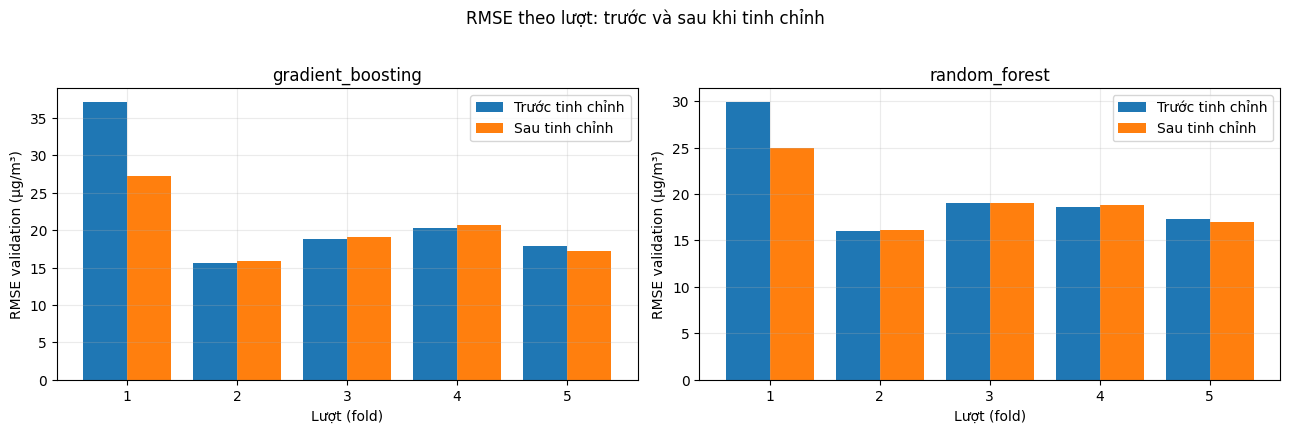

In [25]:
kinds = list(tuning)
fig, axes = plt.subplots(1, len(kinds), figsize=(6.5 * len(kinds), 4.2), squeeze=False)
for ax, kind in zip(axes[0], kinds):
    before = before_by_kind[kind]["rmse"].to_numpy()
    after = tuning[kind]["cv_metrics"]["rmse"].to_numpy()
    positions = np.arange(1, 6)
    ax.bar(positions - 0.2, before, width=0.4, label="Trước tinh chỉnh")
    ax.bar(positions + 0.2, after, width=0.4, label="Sau tinh chỉnh")
    ax.set_xticks(positions)
    ax.set_xlabel("Lượt (fold)")
    ax.set_ylabel("RMSE validation (µg/m³)")
    ax.set_title(kind)
    ax.legend()
fig.suptitle("RMSE theo lượt: trước và sau khi tinh chỉnh", y=1.02)
fig.tight_layout()
save_figure(fig, "tuning_rmse_by_fold.png")
plt.show()

## 9. Xếp hạng theo sổ thí nghiệm (trung bình 5 lượt)

Ghép các dòng `*_cv5` đã có trong `experiment_log.csv` (Persistence, Linear Regression, Random Forest, Gradient Boosting chưa tinh chỉnh) với kết quả tinh chỉnh vừa chạy. Đây là bảng trung bình 5 lượt; đọc kèm lưu ý về lượt 1 ở mục 8. **Chưa có điểm Test.**

In [26]:
DATASET_VERSION = (
    f"beijing_air_quality_standardized.csv; ffill<={FFILL_LIMIT}h; "
    f"lags={'/'.join(map(str, PM25_LAGS))}; "
    f"rolling={'/'.join(map(str, ROLLING_WINDOWS))}"
)
LOG_COLUMNS = ["experiment_id", "model_name", "dataset_version", "mae", "rmse", "r2", "notes"]

tuned_log_rows = []
for kind, info in tuning.items():
    metrics = info["cv_metrics"]
    best_text = ", ".join(
        f"{k.replace('model__', '')}={v}" for k, v in info["best_params"].items()
    )
    tuned_log_rows.append({
        "experiment_id": f"{kind}_tuned_cv5",
        "model_name": MODEL_LABELS[kind] + " - tuned",
        "dataset_version": DATASET_VERSION,
        "mae": round(float(metrics["mae"].mean()), 6),
        "rmse": round(float(metrics["rmse"].mean()), 6),
        "r2": round(float(metrics["r2"].mean()), 6),
        "notes": (
            "Mean of 5 validation folds; shared expanding-window TimeSeriesSplit; "
            f"RandomizedSearchCV n_iter={N_ITER[kind]}, scoring=neg_root_mean_squared_error, "
            f"seed={RANDOM_STATE}; best params: {best_text}; "
            f"search runtime={info['search_seconds']:.1f}s; final fit={info['final_fit_seconds']:.2f}s; "
            "Test not used for tuning or evaluation."
        ),
    })

if EXPERIMENT_LOG.is_file():
    old_log = pd.read_csv(EXPERIMENT_LOG, encoding="utf-8-sig")
else:
    old_log = pd.DataFrame(columns=LOG_COLUMNS)

tuned_ids = [row["experiment_id"] for row in tuned_log_rows]
new_log = pd.concat(
    [old_log[~old_log["experiment_id"].isin(tuned_ids)], pd.DataFrame(tuned_log_rows)],
    ignore_index=True,
)[LOG_COLUMNS]

ranking = new_log[new_log["experiment_id"].str.endswith("_cv5")].copy()
ranking = ranking.sort_values("rmse").reset_index(drop=True)
display(ranking[["experiment_id", "model_name", "mae", "rmse", "r2"]])

,experiment_id,model_name,mae,rmse,r2
0,random_forest_tuned_cv5,Random Forest Regressor - tuned,10.125407,19.177861,0.937670
1,baseline_linreg_cv5,Linear Regression,10.738039,19.294994,0.936331
2,baseline_persistence_cv5,Persistence,10.423993,19.966549,0.931829
3,gradient_boosting_tuned_cv5,Gradient Boosting Regressor (HistGradientBoost...,10.522200,20.038430,0.932782
4,random_forest_cv5,Random Forest Regressor,10.525595,20.170724,0.930914
5,gradient_boosting_cv5,Gradient Boosting Regressor (HistGradientBoost...,11.074285,21.972551,0.917270


## 10. Lưu mô hình, điểm và sổ thí nghiệm

Với mỗi mô hình đã tinh chỉnh, ghi ra (khi `SAVE_ARTIFACTS = True`):
- `models/<tên>_tuned.joblib` và `models/<tên>_tuned_metadata.json` (tham số tốt nhất, khoảng tìm kiếm, hạt giống, phiên bản thư viện, `test_evaluated: false`).
- `outputs/<tên>_tuned_cv_metrics.csv`, `outputs/<tên>_tuned_cv_summary.csv`.
- `outputs/tuning_<tên>_search_results.csv`: bảng toàn bộ các bộ tham số đã thử.
- `outputs/<tên>_tuned_validation_oof_predictions.csv` nếu `SAVE_OOF = True`.
- Cập nhật `experiment_log.csv` (thay các dòng `*_tuned_cv5` cũ nếu có, giữ nguyên dòng khác).

Notebook này **không** đụng tới các file của Notebook 03 và 04 (không ghi đè kết quả "trước tinh chỉnh").

In [27]:
if SAVE_ARTIFACTS:
    MODELS_DIR.mkdir(parents=True, exist_ok=True)
    OUTPUTS_DIR.mkdir(parents=True, exist_ok=True)

    for kind, info in tuning.items():
        model_path = MODELS_DIR / f"{kind}_tuned.joblib"
        metadata_path = MODELS_DIR / f"{kind}_tuned_metadata.json"
        metrics_path = OUTPUTS_DIR / f"{kind}_tuned_cv_metrics.csv"
        summary_path = OUTPUTS_DIR / f"{kind}_tuned_cv_summary.csv"
        search_path = OUTPUTS_DIR / f"tuning_{kind}_search_results.csv"
        oof_path = OUTPUTS_DIR / f"{kind}_tuned_validation_oof_predictions.csv"

        joblib.dump(info["final_model"], model_path, compress=3)
        info["cv_metrics"].to_csv(metrics_path, index=False, encoding="utf-8-sig")
        info["cv_summary"].to_csv(summary_path, index=False, encoding="utf-8-sig")
        info["search_table"].drop(columns=["params"]).to_csv(
            search_path, index=False, encoding="utf-8-sig"
        )
        if SAVE_OOF:
            info["oof"].to_csv(oof_path, index=False, encoding="utf-8-sig")

        cv_metrics = info["cv_metrics"]
        metadata = {
            "model": MODEL_LABELS[kind],
            "pipeline": "build_preprocessor(scale=False) + " + MODEL_LABELS[kind].split()[-1].strip("()"),
            "created_at": datetime.now().isoformat(timespec="seconds"),
            "python_version": sys.version.split()[0],
            "sklearn_version": sklearn.__version__,
            "pandas_version": pd.__version__,
            "target": "PM2.5 at t+1 (same station)",
            "dataset_version": DATASET_VERSION,
            "train_validation_rows": int(len(X_tv)),
            "train_validation_target_period": [
                str(train_validation["target_datetime"].min()),
                str(train_validation["target_datetime"].max()),
            ],
            "test_start": str(TEST_START),
            "test_rows_reserved": int(len(test)),
            "test_used_for_tuning": False,
            "test_evaluated": False,
            "feature_columns": list(FEATURE_COLUMNS),
            "random_state": RANDOM_STATE,
            "tuning": {
                "method": "RandomizedSearchCV",
                "n_iter": int(N_ITER[kind]),
                "scoring": "neg_root_mean_squared_error",
                "cv": "src.cv_folds(n_splits=5), expanding window, same folds as Notebooks 02-04",
                "selection_rule": "lowest mean RMSE over 5 validation folds",
                "search_space": SEARCH_SPACE_TEXT[kind],
                "untuned_params": UNTUNED_PARAMS[kind],
                "best_params": info["best_params"],
                "search_seconds": info["search_seconds"],
            },
            "cv_fold_metrics": json.loads(cv_metrics.to_json(orient="records")),
            "cv_metrics_mean": {m: float(cv_metrics[m].mean()) for m in ["mae", "rmse", "r2"]},
            "cv_metrics_std": {m: float(cv_metrics[m].std(ddof=1)) for m in ["mae", "rmse", "r2"]},
            "cv_rmse_mean_fold2_5": float(cv_metrics["rmse"].iloc[1:].mean()),
            "cv_total_runtime_seconds": info["cv_seconds"],
            "final_fit_seconds": info["final_fit_seconds"],
            "saved_outputs": {
                "model": model_path.relative_to(PROJECT_ROOT).as_posix(),
                "cv_metrics": metrics_path.relative_to(PROJECT_ROOT).as_posix(),
                "cv_summary": summary_path.relative_to(PROJECT_ROOT).as_posix(),
                "search_results": search_path.relative_to(PROJECT_ROOT).as_posix(),
                "validation_oof_predictions": (
                    oof_path.relative_to(PROJECT_ROOT).as_posix() if SAVE_OOF else None
                ),
            },
        }
        metadata_path.write_text(
            json.dumps(metadata, ensure_ascii=False, indent=2), encoding="utf-8"
        )
        print(f"Đã lưu {kind}:", model_path.name, "|", metrics_path.name, "|", search_path.name)

    new_log.to_csv(EXPERIMENT_LOG, index=False, encoding="utf-8-sig")
    print("Đã cập nhật sổ thí nghiệm:", EXPERIMENT_LOG.name, "| thêm/thay:", tuned_ids)
else:
    print("SAVE_ARTIFACTS = False: không ghi file nào.")

Đã lưu gradient_boosting: gradient_boosting_tuned.joblib | gradient_boosting_tuned_cv_metrics.csv | tuning_gradient_boosting_search_results.csv
Đã lưu random_forest: random_forest_tuned.joblib | random_forest_tuned_cv_metrics.csv | tuning_random_forest_search_results.csv
Đã cập nhật sổ thí nghiệm: experiment_log.csv | thêm/thay: ['gradient_boosting_tuned_cv5', 'random_forest_tuned_cv5']


## 11. Kết luận

**Gradient Boosting:**
- Bộ tham số tốt nhất: `learning_rate` ≈ 0,069, `max_iter` 100, `max_leaf_nodes` 127, `min_samples_leaf` 200, `l2_regularization` 1,0 (thử 20 bộ, mất 11,5 phút).
- RMSE trung bình 5 lượt: trước 21,97 → sau 20,04 (giảm 8,8%); trung bình lượt 2-5: trước 18,19 → sau 18,25 (gần như không đổi).
- Học vẹt: tỉ lệ RMSE phần thử / phần học từ 0,89 đến 1,21 ở lượt 2-5 và 1,64 ở lượt 1; nhận xét: không có dấu hiệu học vẹt rõ rệt, lượt 1 cao hơn do phần học chưa có mùa đông.

**Random Forest:**
- Bộ tham số tốt nhất: `n_estimators` 50, `max_depth` không giới hạn, `min_samples_leaf` 20, `max_features` 0,7 (thử 8 bộ, mất 25,5 phút).
- RMSE trung bình 5 lượt: trước 20,17 → sau 19,18 (giảm 4,9%); trung bình lượt 2-5: trước 17,74 → sau 17,74 (không đổi).
- Học vẹt: tỉ lệ RMSE phần thử / phần học từ 0,88 đến 1,13 ở lượt 2-5 và 1,45 ở lượt 1; nhận xét: không có dấu hiệu học vẹt rõ rệt, lượt 1 cao hơn vì lý do tương tự.

**Điều rút ra:** phần cải thiện của việc tinh chỉnh đến gần như hoàn toàn từ lượt 1 (Gradient Boosting RMSE 37,11 → 27,19; Random Forest 29,89 → 24,92). Ở lượt 2-5 điểm không đổi, tức là bộ tham số tốt nhất giúp mô hình thích nghi tốt hơn với mùa đông khi chưa từng thấy mùa đông, chứ không làm mô hình dự đoán chính xác hơn nói chung.

**Xếp hạng (mục 9, trung bình 5 lượt):** mô hình tốt nhất là Random Forest đã tinh chỉnh (RMSE 19,18), tiếp theo là Hồi quy tuyến tính (19,29), Persistence (19,97), Gradient Boosting đã tinh chỉnh (20,04), Random Forest chưa tinh chỉnh (20,17) và Gradient Boosting chưa tinh chỉnh (21,97). So với Hồi quy tuyến tính, Random Forest đã tinh chỉnh chỉ hơn khoảng 0,12 (trong khi độ lệch chuẩn giữa các lượt khoảng 3,4), còn Gradient Boosting đã tinh chỉnh vẫn kém 0,74.

**Hạn chế và việc tiếp theo:**
- Chỉ thử 20 và 8 bộ tham số ngẫu nhiên nên chưa chắc là tối ưu; `min_samples_leaf` (cả hai mô hình) và `max_leaf_nodes` (Gradient Boosting) của bộ tốt nhất nằm sát giá trị lớn nhất được thử, nên có thể có bộ tốt hơn nằm ngoài khoảng tìm kiếm.
- Điểm CV của bộ tốt nhất hơi lạc quan vì được chọn từ nhiều lần thử trên cùng 5 lượt; bộ tốt nhất được chọn theo RMSE trung bình 5 lượt nên bị lượt 1 chi phối.
- Chưa đánh giá trên tập Test: nhóm cần **chốt mô hình và khóa cấu hình** rồi mới chạy Test đúng một lần.